In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n = 2000

age = np.random.uniform(18, 75, n)
revenu = np.random.lognormal(mean=np.log(2800), sigma=0.35, size=n)
revenu = np.clip(revenu, 1200, 9000)
anciennete = np.clip(np.random.exponential(scale=3, size=n), 0, 15)
visites = np.random.poisson(lam=5, size=n)
distance = np.clip(np.random.gamma(shape=2.5, scale=4, size=n), 0.2, 40)

ville = np.random.choice(["Tours", "Paris", "Lyon", "Nantes"], n,
                          p=[0.30, 0.30, 0.20, 0.20])
statut = np.random.choice(["Nouveau", "Régulier", "Fidèle"], n,
                          p=[0.35, 0.45, 0.20])

df = pd.DataFrame({
    "age": age, "revenu": revenu, "anciennete": anciennete,
    "visites": visites, "distance": distance,
    "ville": ville, "statut": statut
})

df.head()

,age,revenu,anciennete,visites,distance,ville,statut
0,39.348787,2059.216379,2.743621,3,19.096238,Nantes,Nouveau
1,72.190715,2096.378418,2.162837,6,10.766789,Nantes,Régulier
2,59.723655,2586.619485,1.019810,8,12.006206,Nantes,Nouveau
3,52.123534,3184.188105,0.019456,4,5.700674,Tours,Régulier
4,26.893063,3855.011678,2.056961,4,4.250496,Paris,Nouveau


In [7]:
effet_revenu = np.clip((revenu - 2000) / 2500, 0, 1.5)
effet_visites = 1.4 / (1 + np.exp(-(visites - 5)))
effet_age = 1.5 * np.exp(-((age - 40) ** 2) / (2 * 12**2))
effet_distance = -0.09 * distance

effet_ville = pd.Series(ville).map({
    "Tours": 0.5, "Paris": 0.2, "Lyon": -0.1, "Nantes": 0.0
}).to_numpy()

effet_statut = pd.Series(statut).map({
    "Nouveau": -0.4, "Régulier": 0.2, "Fidèle": 0.8
}).to_numpy()

score = (-2.4 + 1.2*effet_revenu + effet_visites + effet_age
         + effet_distance + effet_ville + effet_statut)

prob_achat = 1 / (1 + np.exp(-score))
achat = np.random.binomial(1, prob_achat)

df["achat"] = achat
df

,age,revenu,anciennete,visites,distance,ville,statut,achat
0,39.348787,2059.216379,2.743621,3,19.096238,Nantes,Nouveau,0
1,72.190715,2096.378418,2.162837,6,10.766789,Nantes,Régulier,1
2,59.723655,2586.619485,1.019810,8,12.006206,Nantes,Nouveau,0
3,52.123534,3184.188105,0.019456,4,5.700674,Tours,Régulier,0
4,26.893063,3855.011678,2.056961,4,4.250496,Paris,Nouveau,1
...,...,...,...,...,...,...,...,...
1995,55.446444,4678.178000,0.419975,4,14.418802,Paris,Régulier,0
1996,72.527033,1897.555217,1.394866,3,22.422456,Nantes,Régulier,0
1997,21.930607,2765.110131,0.078536,6,3.669093,Tours,Régulier,1
1998,21.252119,2324.744927,0.752236,5,4.522423,Lyon,Fidèle,0


In [ ]:
effet_revenu = np.clip((revenu - 2000) / 2500, 0, 1.5)
effet_visites = 1.4 / (1 + np.exp(-(visites - 5)))
effet_age = 1.5 * np.exp(-((age - 40) ** 2) / (2 * 12**2))
effet_distance = -0.09 * distance

effet_ville = pd.Series(ville).map({
    "Tours": 0.5, "Paris": 0.2, "Lyon": -0.1, "Nantes": 0.0
}).to_numpy()

effet_statut = pd.Series(statut).map({
    "Nouveau": -0.4, "Régulier": 0.2, "Fidèle": 0.8
}).to_numpy()

score = (-2.4 + 1.2*effet_revenu + effet_visites + effet_age
         + effet_distance + effet_ville + effet_statut)
# ici, on créer un score qui calcule la somme de chacune des variable créee précédemment 
# sous la forme d'un array numpy.

prob_achat = 1 / (1 + np.exp(-score))
achat = np.random.binomial(1, prob_achat)

df["achat"] = achat
df.head()

numpy.ndarray

In [ ]:

df_complet = df.copy()
# df.copy() permet de créer une copie indépendante d'un DataFrame Pandas.
df_complet["prob_achat"] = prob_achat
# la commande "df_complet["prob_achat"] = prob_achat" sertà créer une nouvelle colonne qui prendra les
# valeurs du calcul : prob_achat = 1 / (1 + np.exp(-score)) pour chaque lignes.
df_complet

,age,revenu,anciennete,visites,distance,ville,statut,achat,prob_achat
0,39.348787,2059.216379,2.743621,3,19.096238,Nantes,Nouveau,0,0.055958
1,72.190715,2096.378418,2.162837,6,10.766789,Nantes,Régulier,0,0.113226
2,59.723655,2586.619485,1.019810,8,12.006206,Nantes,Nouveau,0,0.132755
3,52.123534,3184.188105,0.019456,4,5.700674,Tours,Régulier,0,0.409096
4,26.893063,3855.011678,2.056961,4,4.250496,Paris,Nouveau,0,0.291210
...,...,...,...,...,...,...,...,...,...
1995,55.446444,4678.178000,0.419975,4,14.418802,Paris,Régulier,0,0.272781
1996,72.527033,1897.555217,1.394866,3,22.422456,Nantes,Régulier,0,0.017757
1997,21.930607,2765.110131,0.078536,6,3.669093,Tours,Régulier,1,0.460900
1998,21.252119,2324.744927,0.752236,5,4.522423,Lyon,Fidèle,0,0.308214


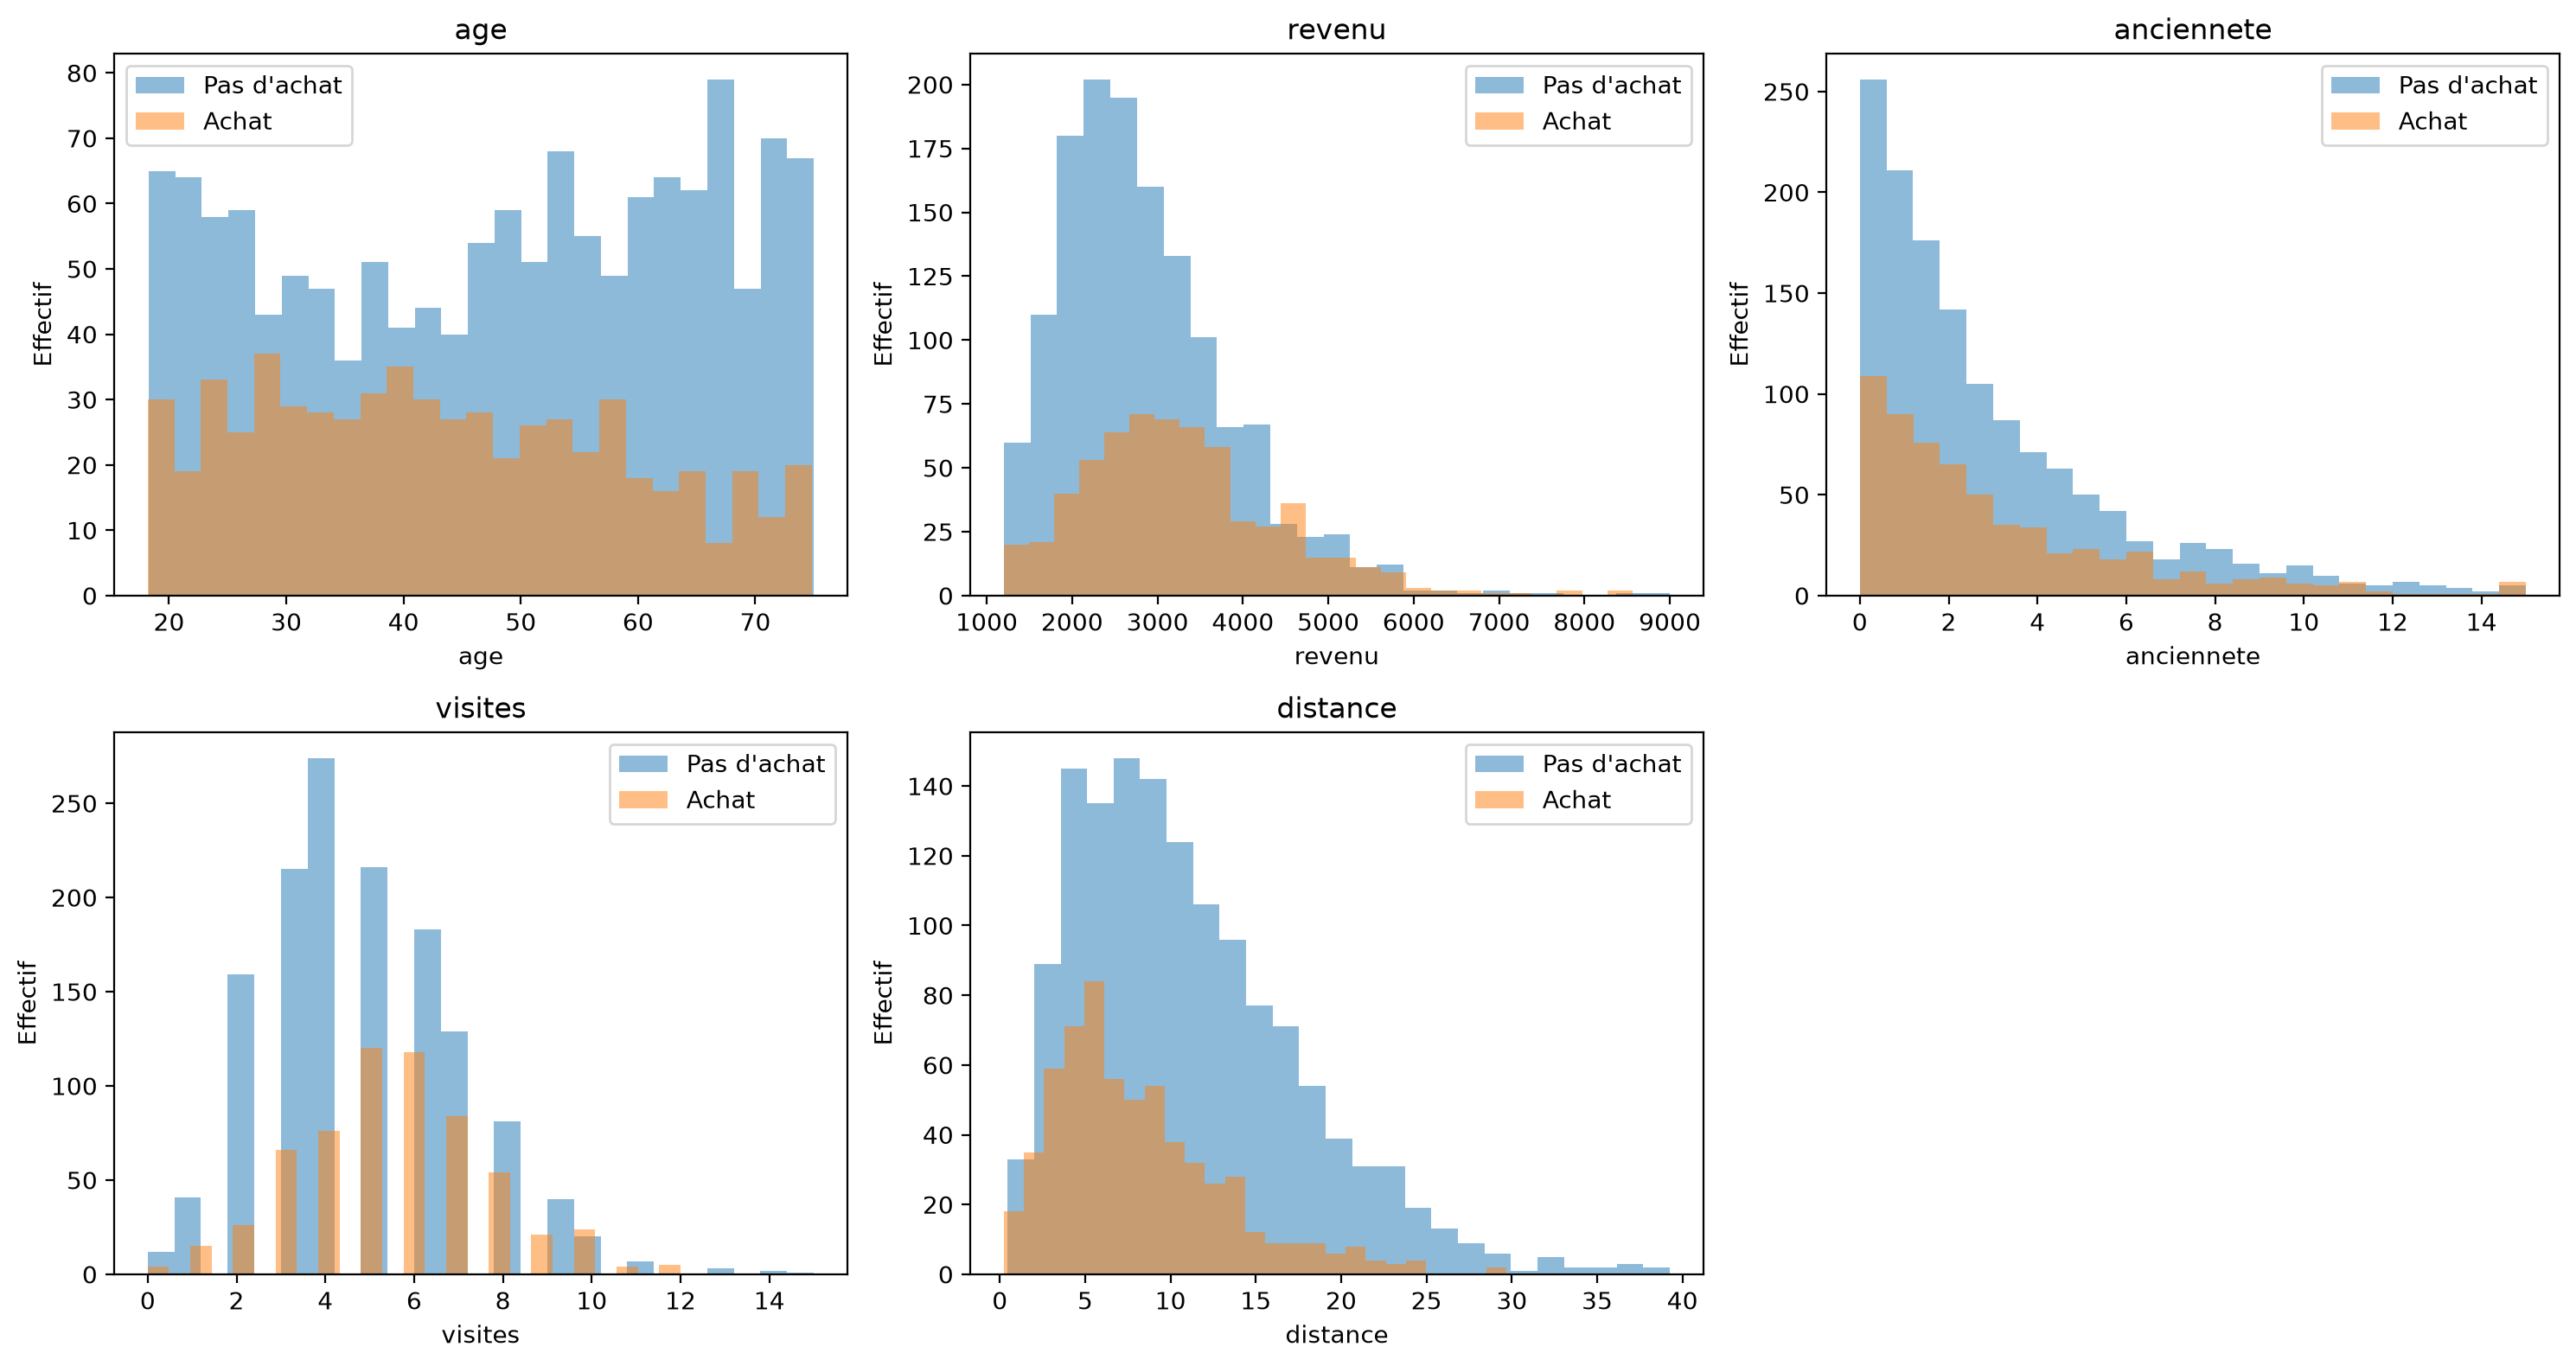

In [11]:
variables_numeriques = ["age", "revenu", "anciennete", "visites", "distance"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, variable in zip(axes.ravel(), variables_numeriques):
    ax.hist(df.loc[df["achat"] == 0, variable], bins=25,
            alpha=0.5, label="Pas d'achat")
    ax.hist(df.loc[df["achat"] == 1, variable], bins=25,
            alpha=0.5, label="Achat")
    ax.set_title(variable)
    ax.set_xlabel(variable)
    ax.set_ylabel("Effectif")
    ax.legend()

axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [19]:
rng = np.random.default_rng(123)

for colonne in ["age", "revenu", "anciennete", "ville"]:
    masque = rng.random(len(df)) < 0.08
    df.loc[masque, colonne] = np.nan

print(df.isna().sum())
print()
print("Taux de valeurs manquantes :")
print(df.isna().mean())

age           146
revenu        162
anciennete    180
visites         0
distance        0
ville         157
statut          0
achat           0
dtype: int64

Taux de valeurs manquantes :
age           0.0730
revenu        0.0810
anciennete    0.0900
visites       0.0000
distance      0.0000
ville         0.0785
statut        0.0000
achat         0.0000
dtype: float64


In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
# on défini "imputer" comme étant l

X_demo = df[["age", "revenu", "anciennete"]]
X_demo_impute = imputer.fit_transform(X_demo)

print("Médianes apprises :", imputer.statistics_)
print(pd.DataFrame(X_demo_impute, columns=X_demo.columns).head())

Médianes apprises : [4.68812351e+01 2.78732483e+03 2.04188310e+00]
         age       revenu  anciennete
0  39.348787  2059.216379    2.743621
1  46.881235  2096.378418    2.162837
2  59.723655  2586.619485    1.019810
3  52.123534  3184.188105    0.019456
4  26.893063  3855.011678    2.041883


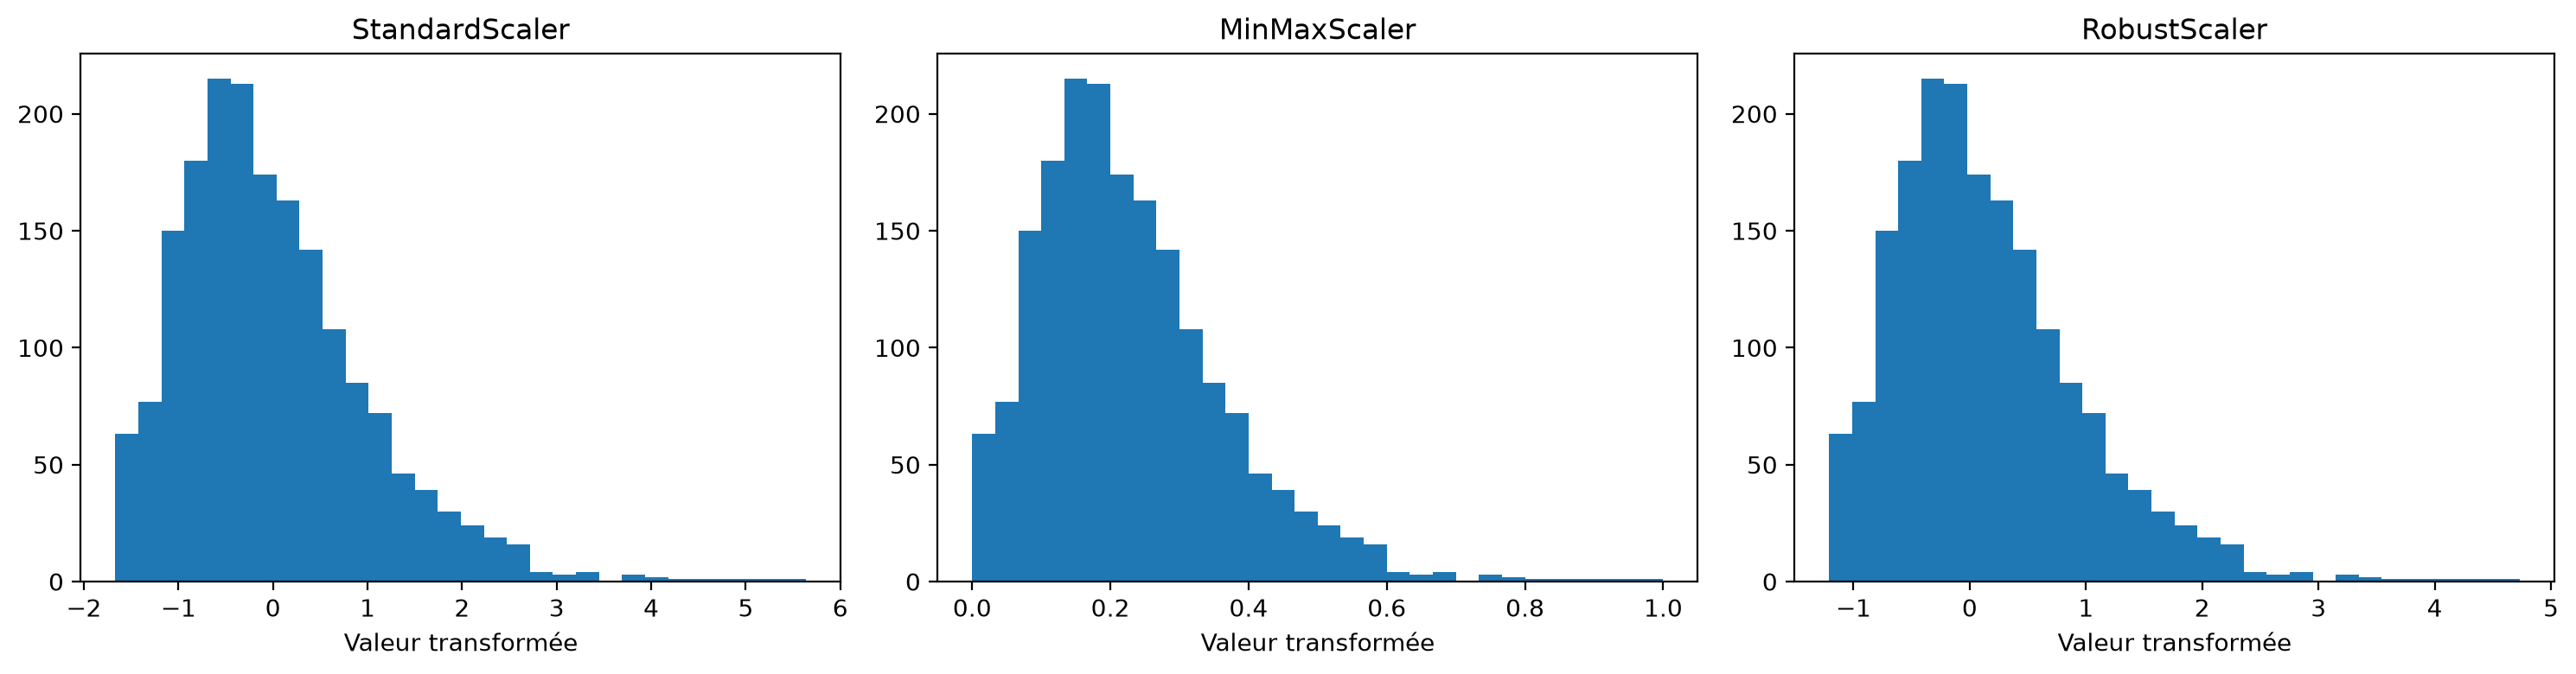

In [21]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

revenu_sans_na = df[["revenu"]].dropna()

scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nom, scaler) in zip(axes, scalers.items()):
    x = scaler.fit_transform(revenu_sans_na)
    ax.hist(x.ravel(), bins=30)
    ax.set_title(nom)
    ax.set_xlabel("Valeur transformée")

plt.tight_layout()
plt.show()